# One LSTM per sensor

**Temporal-stage notebook 4 in `notebooks/temporal/`.** `notebooks/temporal/README.md` says what the notebooks in this folder share, and `01_last_cycle_fd001.ipynb` explains what a temporal stage receives and returns.

## What this notebook is for

This is the temporal stage the paper describes. Its Section 2.2 gives every sensor its own **long short-term memory network**, an LSTM: a small network that reads the sensor's 30 readings one cycle at a time, carries a memory from each cycle to the next, and ends with a summary of the window that it learned to make. That summary, turned into one number, is what the sensor's node carries into the graph layers.

The arrangement — one network per sensor — is the paper's. Its size is not: the paper gives no width for the memory, no number of layers and no way of turning the memory into one number, and this project chose all three (assumption A-26).

The notebook loads a trained network from a stored run, follows T50's 30 readings through T50's own trained LSTM by hand, first one cycle and then all thirty, and checks every number against PyTorch's. Then it counts what the stage costs and lists its stored results.

## What it does not do

- **It does not train anything.** The network is seed 42 of a stored five-seed run.
- **It does not explain what the trained network learned.** It shows what the network computes on one window and how its output moves with T50's readings; why it learned that is a different question.
- **It does not compare this stage with another.** `07_comparison_fd001.ipynb` does that.

## The notebook in one list

| # | Step | What goes in | What comes out |
|---|------|--------------|----------------|
| 1 | **Load the trained network and the window** | a stored run of this stage, seed 42 | the network, checked against the run; the held-back engine's last window |
| 2 | **Cycle 1 by hand** | T50's first reading, an empty memory | the four gates, the memory and the output, for three of the 32 memory slots |
| 3 | **Cycle 2 by hand** | T50's second reading, cycle 1's output | the same, now with the previous output taking part |
| 4 | **All thirty cycles, and the number handed on** | T50's 30 readings | the memory cycle by cycle, and the one number T50's node receives |
| 5 | **Count the cost** | the network built with this stage | learned numbers, worked out by hand and counted |
| 6 | **Read the stored results** | `reports/` | every stored five-seed run of this stage under this folder's settings |

## 1. Background

### Why a memory, and why gates

A network that reads 30 readings one at a time has to carry what it has seen so far from each reading to the next. That carried list of numbers is its **memory**. The simplest recurrent network rewrites the whole list at every reading, `h_t = tanh(W · [h_{t−1}, x_t] + b)`, so what it saw 25 readings ago survives only if every rewrite since happened to preserve it.

The LSTM (Hochreiter and Schmidhuber, 1997), in the form the paper prints with the keep gate that Gers et al. (2000) added to it, keeps a second list, the **cell state**, which it changes only as far as three **gates** allow. A gate is a list of numbers between 0 and 1, one per memory slot, multiplied into something to let a fraction of it through. A slot whose keep gate is near 1 and whose add gate is near 0 carries its value unchanged to the next cycle. That is what lets an early reading reach the end of the window.

### The calculations at one cycle

The paper prints them as its Equations 1 to 6 (page 4). This notebook calls the forget, input and output gates **keep**, **add** and **expose**, after what each does.

```
f_t = σ(W_f · [h_{t−1}, x_t] + b_f)        keep gate      (the paper's forget gate)
i_t = σ(W_i · [h_{t−1}, x_t] + b_i)        add gate       (its input gate)
C̃_t = tanh(W_C · [h_{t−1}, x_t] + b_C)     proposal       (its candidate values)
C_t = f_t ⊙ C_{t−1} + i_t ⊙ C̃_t            new memory     (its cell state)
o_t = σ(W_o · [h_{t−1}, x_t] + b_o)        expose gate    (its output gate)
h_t = o_t ⊙ tanh(C_t)                       new output     (its hidden state)
```

- `t` is the cycle, 1 to 30 within the window; `t − 1` is the cycle before.
- `x_t` is the sensor's reading at cycle `t`: one number.
- `h_{t−1}` is the previous cycle's output, 32 numbers here, all zero before the first cycle; `[h_{t−1}, x_t]` is the two joined into 33.
- `W_f`, `W_i`, `W_C`, `W_o` are learned multipliers, 32 rows of 33 each; `b_f`, `b_i`, `b_C`, `b_o` are learned offsets, 32 each.
- `σ` is the sigmoid, `1 / (1 + e^(−z))`, which squashes any number into the range 0 to 1 — that is what makes a gate a fraction. `tanh` squashes into −1 to 1.
- `⊙` multiplies two lists slot by slot.
- `C_t` is the cell state and `h_t` the output, 32 numbers each.

**A tiny example, one slot.** Say the memory holds 0.5, and at this cycle keep = 0.9, add = 0.2, proposal = −0.4, expose = 0.5:

```
new memory  =  0.9 × 0.5  +  0.2 × (−0.4)  =  0.45 − 0.08  =  0.37
new output  =  0.5 × tanh(0.37)  =  0.5 × 0.3540  =  0.1770
```

The memory kept most of what it held and took in a little of the proposal; the output exposed half of the squashed memory.

### In PyTorch's terms

`torch.nn.LSTM` stores each `W` in two pieces — the multipliers of the reading, `weight_ih`, and those of the previous output, `weight_hh` — so `W · [h_{t−1}, x_t]` becomes `weight_hh · h_{t−1} + weight_ih · x_t`. It also keeps two offset lists, `bias_ih` and `bias_hh`. They are always added together, so they act as the paper's single `b`, but both are learned, and both count in step 5. The four gates are stacked in the order add, keep, proposal, expose: rows 1 to 32 of each piece belong to the add gate, rows 33 to 64 to the keep gate, and so on.

### One network per sensor, and one number out

"Each sensor s∈{1, 2, …, n} is associated with a dedicated LSTM network", the paper says (Section 2.2, page 4), and its Equation 7 writes the result as `h_t^(s)`, one per sensor. So this stage holds fourteen LSTMs, each reading only its own sensor's 30 readings, each with its own learned numbers. Its memory width, 32, and its single layer are this project's choices (assumption A-26).

After the 30th cycle the stage keeps that cycle's output, `h_30`, and turns its 32 numbers into the one number Table 4 requires with a **projection**: `y = w · h_30 + b`, 32 learned multipliers and one learned offset, the same for all fourteen sensors (assumption A-26). The memory starts at zero for every window.

**Do not confuse** the cell state, the memory the gates protect, with the hidden state, the output computed from it at each cycle. **Do not confuse** the learned numbers, fixed once training ends and the same for every window, with the memory, recomputed from zero for every window. And **do not confuse** the 32 memory slots with the 30 cycles: the slots are the width of the memory, the cycles are how many times it is updated.

## 2. Setup

In [1]:
from __future__ import annotations

import logging
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml
from IPython.display import display

# The project's top folder is the nearest one above this notebook that holds
# pyproject.toml. Adding its src/ folder to Python's search path makes the
# package importable from a clone that was never installed.
PROJECT_ROOT = next(
    folder for folder in (Path.cwd(), *Path.cwd().parents)
    if (folder / "pyproject.toml").is_file()
)
sys.path.insert(0, str(PROJECT_ROOT / "src"))

try:
    import torch
except ImportError as missing:
    raise ImportError(
        "This notebook loads a trained network, which needs PyTorch, and PyTorch is "
        'not installed. Install the project with  pip install -e ".[model]"'
    ) from missing

from thesis_gnn_rul_xai.config import load_config
from thesis_gnn_rul_xai.models import ModelConfig, build_model
from thesis_gnn_rul_xai.training import evaluate_model, load_seed, read_run
from thesis_gnn_rul_xai.training import TrainingConfig, find_runs
from thesis_gnn_rul_xai.utils.logging_setup import configure_logging

configure_logging(logging.ERROR)
pd.set_option("display.width", 120)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_colwidth", None)    # a run's folder name is printed whole
plt.rcParams.update({"figure.dpi": 110, "font.size": 9})

print(f"Project root: {PROJECT_ROOT}")
print(f"PyTorch     : {torch.__version__}")

Project root: D:\Main\University\Thesis\Code\Thesis GNN RUL XAI
PyTorch     : 2.13.0+cpu


## 3. The trained network and the window

### Step 1 — Load the trained network and the window

**What.** Load seed 42 of the sensitivity study's five-seed run of this stage, the run whose settings are printed in `notebooks/temporal/README.md`, together with its data rebuilt exactly as it was trained. Then take the same window every notebook in this folder works on.

**Why.** A recurrent stage computes nothing meaningful until it is trained, so the worked example needs trained numbers, and a stored run records the commit of the code that trained them (working rule 3a). The network was trained on a graphics card and is scored here on the processor, so the check allows a difference in the last digits and prints it.

**Check.** The loaded network must score the test engines as the run recorded for seed 42, to within 0.0001 cycles; the run's settings must be this folder's; the window must pass the same checks as in every notebook here.

In [2]:
config = load_config(PROJECT_ROOT / "config" / "fd001.yaml")
RUN = PROJECT_ROOT / "reports" / "sensitivity_fd65a3b-dirty_20260929T101059Z" / "runs" / "FD001" / "reference"
if not (RUN / "summary.json").is_file():
    raise FileNotFoundError(
        f"{RUN} is not in reports/. It is the sensitivity study's five-seed run of this stage. "
        "A run with the same settings is made with\n\n"
        "    python scripts/train.py --config config/fd001.yaml --temporal lstm --seeds 5\n\n"
        "after which RUN above must name the folder it writes."
    )
run = read_run(RUN)
SEED = 42
network, prepared = load_seed(run, SEED)

recorded = float(run.results.set_index("seed").loc[SEED, "rmse"])
scored = evaluate_model(network, prepared.test)["rmse"]
same_network = abs(scored - recorded) < 1e-4
assert same_network
without_notes = lambda settings: {k: v for k, v in settings.to_dict().items() if k != "notes"}
same_settings = (without_notes(run.preprocessing) == without_notes(config)
                 and run.model_config == ModelConfig(temporal="lstm"))
assert same_settings
command = run.summary["command"]
device = command[command.index("--device") + 1] if "--device" in command else "auto"
print(f"Stored run : {RUN.relative_to(PROJECT_ROOT).as_posix()}")
print(f"Commit     : {run.summary['commit']}   trained with --device {device}, "
      f"PyTorch {run.summary['environment']['packages']['torch']}")
print(f"OK  seed {SEED}'s network scores the test engines at {scored:.6f} cycles here; the run "
      f"recorded {recorded:.6f} ({scored - recorded:+.1e}).")
print("OK  the run's preprocessing is config/fd001.yaml's, and its network is this stage's default.")

Stored run : reports/sensitivity_fd65a3b-dirty_20260929T101059Z/runs/FD001/reference
Commit     : fd65a3b-dirty   trained with --device cuda, PyTorch 2.5.1+cu121
OK  seed 42's network scores the test engines at 13.015376 cycles here; the run recorded 13.015374 (+1.5e-06).
OK  the run's preprocessing is config/fd001.yaml's, and its network is this stage's default.


In [3]:
sensors = list(prepared.sensor_symbols)

# The held-back engine with the most windows, and its last window.
held_back = prepared.validation
units, counts = np.unique(held_back.units, return_counts=True)
ENGINE = int(units[np.argmax(counts)])
engine_rows = np.flatnonzero(held_back.units == ENGINE)
engine_rows = engine_rows[np.argsort(held_back.end_cycles[engine_rows])]

SENSOR = "T50"
s = sensors.index(SENSOR)
window = held_back.features[engine_rows[-1]]             # (14 sensors, 30 cycles)
end_cycle = int(held_back.end_cycles[engine_rows[-1]])
cycles = np.arange(end_cycle - window.shape[1] + 1, end_cycle + 1)
readings = window[s]                                     # T50's 30 readings, oldest first

print(f"Engine {ENGINE}: {len(engine_rows)} windows, held back from training under seed {config.seed}.")
print(f"Worked window: cycles {cycles[0]} to {cycles[-1]}, shape {window.shape}, "
      f"remaining life at its end {held_back.targets[engine_rows[-1]]:.0f} cycles.\n")
display(pd.DataFrame([readings], index=[f"{SENSOR} reading"],
                     columns=pd.MultiIndex.from_arrays([range(1, 31), cycles],
                                                       names=["position", "engine cycle"])).round(6))

window_checks = {
    "the window is 14 sensors by 30 cycles": window.shape == (14, 30),
    "its engine is not a training engine": ENGINE not in set(prepared.train.units),
    "it ends at the cycle the engine failed": float(held_back.targets[engine_rows[-1]]) == 0.0,
}
assert all(window_checks.values()), window_checks
print("OK  " + "; ".join(window_checks))

Engine 5: 240 windows, held back from training under seed 42.
Worked window: cycles 240 to 269, shape (14, 30), remaining life at its end 0 cycles.



position,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26,27,28,29,30
engine cycle,240,241,242,243,244,245,246,247,248,249,250,251,252,253,254,255,256,257,258,259,260,261,262,263,264,265,266,267,268,269
T50 reading,1.292245,1.830854,1.37155,1.249616,1.447051,1.508854,1.587562,1.273505,1.471704,1.650684,1.835789,1.791576,1.52075,1.631635,1.756066,2.040374,2.416119,2.142862,2.213197,1.791471,1.891658,1.690612,1.812787,1.652386,1.828773,1.867343,2.481498,2.537435,2.828042,2.74036


OK  the window is 14 sensors by 30 cycles; its engine is not a training engine; it ends at the cycle the engine failed


## 4. The stage, step by step

### Step 2 — Cycle 1, by hand

**What.** Take T50's own LSTM out of the trained network, and compute cycle 1 with NumPy: the four gates, the new memory and the new output. The table shows the first three of the 32 memory slots; the other 29 are computed the same way.

**Why.** At cycle 1 the previous output is all zeros, so every gate is just a multiplier times the reading plus an offset. It is the simplest cycle there is, and every later cycle repeats it with one more term.

In [4]:
cell = network.temporal.cells[s]                       # T50's own LSTM, one of fourteen
H = cell.hidden_size                                   # 32 memory slots
w_reading = cell.weight_ih_l0.detach().double().numpy()[:, 0]   # (128,)    multipliers of the reading
w_output = cell.weight_hh_l0.detach().double().numpy()          # (128, 32) multipliers of the previous output
offset = (cell.bias_ih_l0 + cell.bias_hh_l0).detach().double().numpy()   # (128,) the two offsets, added
GATES = {"add": slice(0, H), "keep": slice(H, 2 * H), "proposal": slice(2 * H, 3 * H),
         "expose": slice(3 * H, 4 * H)}
x = readings.astype(np.float64)
SLOTS = [0, 1, 2]


def sigmoid(z):
    return 1.0 / (1.0 + np.exp(-z))


def lstm_cycle(reading, previous_output, previous_memory):
    """One cycle of the paper's Equations 1 to 6, for all 32 slots at once."""
    total = w_reading * reading + w_output @ previous_output + offset
    add, keep = sigmoid(total[GATES["add"]]), sigmoid(total[GATES["keep"]])
    proposal, expose = np.tanh(total[GATES["proposal"]]), sigmoid(total[GATES["expose"]])
    memory = keep * previous_memory + add * proposal
    return {"total": total, "add": add, "keep": keep, "proposal": proposal, "expose": expose,
            "memory": memory, "output": expose * np.tanh(memory)}


def gate_table(step, reading, previous_output):
    rows = []
    for gate, part in GATES.items():
        for k in SLOTS:
            rows.append({"gate": gate, "slot": k + 1,
                         "multiplier × reading": w_reading[part][k] * reading,
                         "from the previous output": (w_output[part] @ previous_output)[k],
                         "offset": offset[part][k], "sum": step["total"][part][k],
                         "squashed": step[gate][k]})
    return pd.DataFrame(rows).set_index(["gate", "slot"])


zero = np.zeros(H)
first = lstm_cycle(x[0], zero, zero)
print(f"Cycle 1 of the window (engine cycle {cycles[0]}): reading {x[0]:.6f}; "
      "previous output and memory all zero.")
display(gate_table(first, x[0], zero).round(6))
for k in SLOTS:
    print(f"slot {k + 1}: memory = keep × 0 + add × proposal = {first['add'][k]:.6f} × "
          f"{first['proposal'][k]:+.6f} = {first['memory'][k]:+.6f};   output = expose × tanh(memory) = "
          f"{first['expose'][k]:.6f} × {np.tanh(first['memory'][k]):+.6f} = {first['output'][k]:+.6f}")

Cycle 1 of the window (engine cycle 240): reading 1.292245; previous output and memory all zero.


multiplier × reading  from the previous output    offset       sum  squashed
gate     slot                                                                              
add      1                -0.027627                       0.0 -0.314276 -0.341904  0.415347
         2                 0.338996                       0.0 -0.118903  0.220094  0.554802
         3                -0.062921                       0.0 -0.052705 -0.115626  0.471126
keep     1                 0.156794                       0.0 -0.159494 -0.002699  0.499325
         2                 0.307551                       0.0 -0.066328  0.241223  0.560015
         3                -0.409849                       0.0  0.085584 -0.324265  0.419637
proposal 1                -0.022162                       0.0 -0.025904 -0.048065 -0.048029
         2                -0.044863                       0.0 -0.239614 -0.284477 -0.277043
         3                -0.511124                       0.0  0.061273 -0.449851 -0.421777
expose   1                 0.003078                       0.0 -0.083211 -0.080133  0.479977
         2                 0.438220                       0.0 -0.119107  0.319113  0.579108
         3                -0.307512                       0.0 -0.111664 -0.419176  0.396714

slot 1: memory = keep × 0 + add × proposal = 0.415347 × -0.048029 = -0.019949;   output = expose × tanh(memory) = 0.479977 × -0.019946 = -0.009574
slot 2: memory = keep × 0 + add × proposal = 0.554802 × -0.277043 = -0.153704;   output = expose × tanh(memory) = 0.579108 × -0.152505 = -0.088317
slot 3: memory = keep × 0 + add × proposal = 0.471126 × -0.421777 = -0.198710;   output = expose × tanh(memory) = 0.396714 × -0.196135 = -0.077810


**Reading the table.** With nothing remembered, each gate's sum has two parts: a multiplier times the reading, 1.292245, and an offset. For these three slots the sums of the three gates fall between −0.42 and +0.32, and a sigmoid turns numbers that small into fractions near one half: between 0.40 and 0.58. So at cycle 1 each slot takes in about half of its proposal (keeping half of an empty memory adds nothing) and exposes about half of the squashed result. Slot 1's memory becomes 0.415347 × (−0.048029) = −0.019949, and its output 0.479977 × tanh(−0.019949) = −0.009574.

### Step 3 — Cycle 2, by hand

**What.** The same calculation for cycle 2. Now the previous output, cycle 1's 32 numbers, takes part: each gate of each slot adds 32 products, one per slot of the previous output. The cell prints the first three of those products for the keep gate of slot 1, then their total, then the same table as before.

**Why.** This term is the whole difference between a recurrent network and one that reads each cycle on its own: through it, what the network computed at cycle 1 changes what it computes at cycle 2.

In [5]:
second = lstm_cycle(x[1], first["output"], first["memory"])
row = w_output[GATES["keep"]][0]                       # slot 1 of the keep gate: 32 multipliers
products = row * first["output"]
print("Keep gate, slot 1, from the previous output: "
      + " + ".join(f"({row[j]:+.4f} × {first['output'][j]:+.4f})" for j in range(3))
      + f" + ... 29 more = {products.sum():+.6f}\n")
print(f"Cycle 2 (engine cycle {cycles[1]}): reading {x[1]:.6f}.")
display(gate_table(second, x[1], first["output"]).round(6))
k = 0
print(f"slot 1: memory = keep × previous memory + add × proposal = {second['keep'][k]:.6f} × "
      f"{first['memory'][k]:+.6f} + {second['add'][k]:.6f} × {second['proposal'][k]:+.6f} "
      f"= {second['memory'][k]:+.6f}")

Keep gate, slot 1, from the previous output: (-0.1031 × -0.0096) + (+0.1796 × -0.0883) + (+0.1154 × -0.0778) + ... 29 more = -0.014940

Cycle 2 (engine cycle 241): reading 1.830854.


multiplier × reading  from the previous output    offset       sum  squashed
gate     slot                                                                              
add      1                -0.039143                 -0.017409 -0.314276 -0.370827  0.408341
         2                 0.480291                  0.118709 -0.118903  0.480097  0.617771
         3                -0.089147                 -0.098185 -0.052705 -0.240037  0.440277
keep     1                 0.222146                 -0.014940 -0.159494  0.047713  0.511926
         2                 0.435739                  0.088942 -0.066328  0.458353  0.612623
         3                -0.580675                 -0.190654  0.085584 -0.685745  0.334980
proposal 1                -0.031399                  0.072125 -0.025904  0.014823  0.014822
         2                -0.063561                 -0.164734 -0.239614 -0.467910 -0.436509
         3                -0.724162                 -0.090738  0.061273 -0.753627 -0.637308
expose   1                 0.004362                 -0.033441 -0.083211 -0.112291  0.471957
         2                 0.620871                  0.244826 -0.119107  0.746590  0.678435
         3                -0.435684                  0.066502 -0.111664 -0.480846  0.382052

slot 1: memory = keep × previous memory + add × proposal = 0.511926 × -0.019949 + 0.408341 × +0.014822 = -0.004160


### Step 4 — All thirty cycles, and the number handed on

**What.** Run the same calculation through all 30 cycles. At each cycle, also apply the projection to that cycle's output, which gives the number the stage *would* hand on if the window ended there. At cycle 30 it is the number T50's node does receive.

**Why.** The table shows how the memory moves as T50 climbs, and the last row is the stage's whole result for this sensor.

**Check.** The 30 outputs computed by hand must match PyTorch's own LSTM at every cycle, and the final number must match what the trained stage hands T50's node, both to within 0.00001.

In [6]:
w_project = network.temporal.project.weight.detach().double().numpy()[0]   # (32,), shared by all sensors
b_project = float(network.temporal.project.bias.detach())

output, memory, trace, outputs, keeps = zero, zero, [], [], []
for t in range(30):
    step = lstm_cycle(x[t], output, memory)
    output, memory = step["output"], step["memory"]
    outputs.append(output)
    keeps.append(step["keep"])
    trace.append({"engine cycle": cycles[t], "reading": x[t], "keep, average of 32": step["keep"].mean(),
                  "add, average of 32": step["add"].mean(),
                  "handed on if the window ended here": w_project @ output + b_project})
trace = pd.DataFrame(trace, index=pd.Index(range(1, 31), name="position"))
display(trace.round(4))
keeps = np.array(keeps)                                # (30 cycles, 32 slots)
print(f"Keep gates over all 32 slots and 30 cycles: from {keeps.min():.4f} to {keeps.max():.4f}; "
      f"{(keeps > 0.9).sum()} of {keeps.size} above 0.9.\n")

terms = w_project * output
print("Projection of cycle 30's output: "
      + " + ".join(f"({w_project[j]:+.4f} × {output[j]:+.4f})" for j in range(3))
      + f" + ... 29 more + offset {b_project:+.4f} = {terms.sum() + b_project:+.6f}")

with torch.no_grad():
    torch_outputs = cell(torch.from_numpy(window[s][None, :, None]))[0][0].double().numpy()   # (30, 32)
    handed_on = network.temporal(torch.from_numpy(window[None]))                              # (1, 14, 1)
hand_matches_lstm = bool(np.abs(np.array(outputs) - torch_outputs).max() < 1e-5)
hand_matches_stage = bool(abs(trace.iloc[-1, -1] - float(handed_on[0, s, 0])) < 1e-5)
assert hand_matches_lstm and hand_matches_stage
print(f"\nOK  the hand outputs match PyTorch's LSTM at all 30 cycles "
      f"(largest gap {np.abs(np.array(outputs) - torch_outputs).max():.1e}), and the stage hands "
      f"T50's node {float(handed_on[0, s, 0]):.6f}.\n")
print("What the stage hands every sensor's node for this window:")
display(pd.DataFrame({"handed on": handed_on[0, :, 0].numpy()}, index=sensors).T.round(4))

,engine cycle,reading,"keep, average of 32","add, average of 32",handed on if the window ended here
position,,,,,
1,240,1.2922,0.5202,0.5319,-0.4192
2,241,1.8309,0.5361,0.5552,-0.8983
3,242,1.3715,0.5429,0.5639,-1.1798
4,243,1.2496,0.5484,0.5716,-1.3591
5,244,1.4471,0.5532,0.5813,-1.5265
6,245,1.5089,0.5554,0.5886,-1.6509
7,246,1.5876,0.5564,0.5948,-1.7453
8,247,1.2735,0.5539,0.5938,-1.7395
9,248,1.4717,0.5533,0.5967,-1.7683


Keep gates over all 32 slots and 30 cycles: from 0.0719 to 0.9713; 29 of 960 above 0.9.

Projection of cycle 30's output: (+0.0661 × -0.2353) + (+0.1710 × -0.6925) + (+0.2081 × -0.1629) + ... 29 more + offset -0.0234 = -2.165775



OK  the hand outputs match PyTorch's LSTM at all 30 cycles (largest gap 1.2e-07), and the stage hands T50's node -2.165775.

What the stage hands every sensor's node for this window:


,T24,T30,T50,P15,P30,Nf,Nc,Ps30,phi,NRf,BPR,htBleed,W31,W32
handed on,1.8721,-0.9358,-2.1658,-0.1103,-0.4796,0.0642,-2.8786,-1.8334,-0.7361,0.3433,0.6693,-0.316,-0.333,-0.6622


**Reading the table.** Two things stand out. First, the number the stage would hand on falls steeply over the first seven cycles, from −0.42 to −1.75, while T50 itself only wavers between 1.25 and 1.83. That fall is the memory filling up from zero, not anything T50 did: every window starts with an empty memory, so the stage's values for the first few cycles describe its own start. Second, after that the number moves against T50. When T50 jumps over the last four cycles, from 1.87 to between 2.48 and 2.83, the number falls from −1.87 to −2.17, its lowest in the window.

The keep gates average between 0.52 and 0.56 over the 32 slots at every cycle, but single gates range from 0.07 to 0.97. Of the 960 computed here, 32 slots at 30 cycles, 29 are above 0.9, and a slot whose keep gate stays that high carries most of its memory on to the next cycle: that is how something seen early in the window can still count at its end.

The figure sets the stage's output beside T50's readings, first within the worked window and then across every window of the engine's life.

Across engine 5's 240 windows, the correlation of T50's handed-on number with
  the window's newest reading  -0.967
  the window's average         -0.977


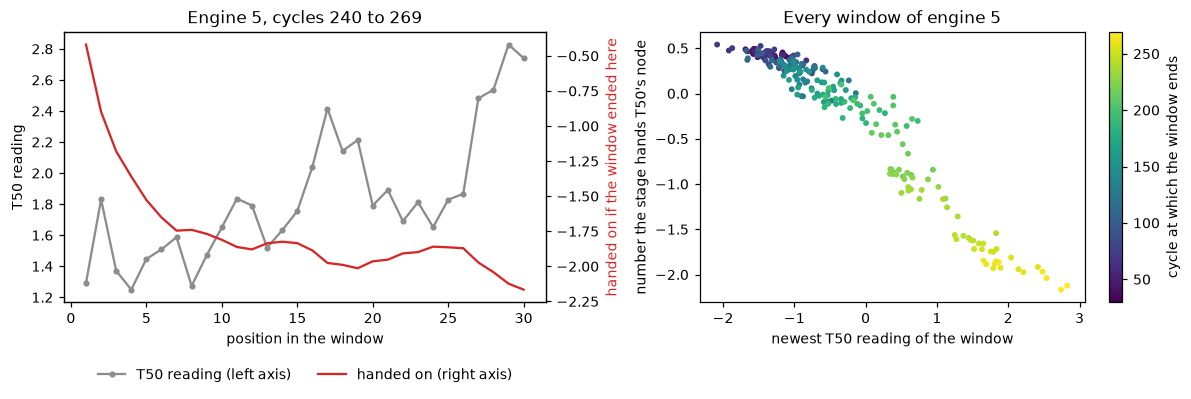

In [7]:
with torch.no_grad():
    life_out = network.temporal(torch.from_numpy(held_back.features[engine_rows]))[:, s, 0].numpy()
life_newest = held_back.features[engine_rows, s, -1]
life_average = held_back.features[engine_rows, s, :].mean(axis=1)
with_newest = np.corrcoef(life_out, life_newest)[0, 1]
with_average = np.corrcoef(life_out, life_average)[0, 1]
print(f"Across engine {ENGINE}'s {len(engine_rows)} windows, the correlation of T50's handed-on number with")
print(f"  the window's newest reading  {with_newest:+.3f}")
print(f"  the window's average         {with_average:+.3f}")

figure, (left, right) = plt.subplots(1, 2, figsize=(11, 3.8))
reading_line, = left.plot(trace.index, trace["reading"], "o-", color="0.55", markersize=3,
                         label=f"{SENSOR} reading (left axis)")
left.set(xlabel="position in the window", ylabel=f"{SENSOR} reading",
         title=f"Engine {ENGINE}, cycles {cycles[0]} to {cycles[-1]}")
twin = left.twinx()
handed_line, = twin.plot(trace.index, trace["handed on if the window ended here"], color="C3",
                         label="handed on (right axis)")
twin.set_ylabel("handed on if the window ended here", color="C3")
# One legend for both lines, under the panel, where it covers neither.
left.legend(handles=[reading_line, handed_line], loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=2,
            frameon=False)
dots = right.scatter(life_newest, life_out, s=8, c=held_back.end_cycles[engine_rows], cmap="viridis")
figure.colorbar(dots, ax=right, label="cycle at which the window ends")
right.set(xlabel=f"newest {SENSOR} reading of the window", ylabel="number the stage hands T50's node",
          title=f"Every window of engine {ENGINE}")
figure.tight_layout()
plt.show()

A **correlation** is a number from −1 to +1 that says how closely two lists of numbers follow a straight line together: +1 when one rises in exact proportion as the other rises, −1 when one falls in exact proportion as the other rises, and 0 when no straight line relates them.

**Across the engine's life** (right), the number this network hands T50's node falls steadily as T50's newest reading rises: their correlation over the 240 windows is −0.967, and with the window's average it is −0.977. The sign carries no meaning on its own, because the first graph layer multiplies the number by 32 learned multipliers, any of which can be negative. What the correlation says is that for T50 this trained stage hands on something that tracks where T50 sits, a little more closely the window's average than its newest reading.

It is one network, seed 42's. A different seed trains a different stage, and nothing here says the same holds for the other 13 sensors or the other seeds.

### Step 5 — What it costs

**What.** Work out the stage's learned numbers by hand from the shapes in section 1, then build the network with this stage, and with one LSTM shared by all sensors, and count.

**Why.** This stage is the only part of the paper's network whose size the paper never gives, and the size this project chose (assumption A-26) roughly doubles the network.

**Check.** The hand count must equal the count of the built networks and of the loaded one.

In [8]:
TABLE_4_NAMES = {"graph_layers.0": "GCN-1", "graph_layers.1": "GCN-2",
                 "graph_layers.2": "GCN-3", "fc1": "FC-1", "fc2": "FC-2"}


def parameter_table(network):
    """Learned numbers in each part of a network, the temporal stage first."""
    parts = {"temporal stage": 0}
    for name, parameter in network.named_parameters():
        part = "temporal stage" if name.startswith("temporal.") else TABLE_4_NAMES[name.rsplit(".", 1)[0]]
        parts[part] = parts.get(part, 0) + parameter.numel()
    parts["whole network"] = sum(parts.values())
    return pd.DataFrame({"learned numbers": parts})


per_cell = 4 * H * 1 + 4 * H * H + 2 * 4 * H     # reading multipliers + output multipliers + two offset lists
projection = H + 1
by_hand = {"one LSTM": per_cell, "the stage, 14 LSTMs and the projection": 14 * per_cell + projection,
           "the stage, one shared LSTM and the projection": per_cell + projection}
print(f"one LSTM: 4 × {H} × 1 + 4 × {H} × {H} + 2 × 4 × {H} = {4 * H} + {4 * H * H} + {8 * H} = {per_cell:,}")
print(f"the stage: 14 × {per_cell:,} + ({H} + 1) = {14 * per_cell + projection:,}")
print(f"shared:    {per_cell:,} + ({H} + 1) = {per_cell + projection:,}\n")

built = {}
for name, shared in (("one LSTM per sensor", False), ("one LSTM for all sensors", True)):
    model = build_model(prepared.adjacency_normalized, ModelConfig(temporal="lstm", shared_across_sensors=shared),
                        window_size=config.window_size, rul_max=config.rul_max)
    built[name] = parameter_table(model)["learned numbers"]
costs = pd.DataFrame(built)
display(costs.T)
cost_checks = {
    "one LSTM per sensor": int(costs.loc["temporal stage", "one LSTM per sensor"]) == by_hand["the stage, 14 LSTMs and the projection"],
    "one shared LSTM": int(costs.loc["temporal stage", "one LSTM for all sensors"]) == by_hand["the stage, one shared LSTM and the projection"],
    "the loaded network": network.count_parameters() == int(costs.loc["whole network", "one LSTM per sensor"]),
    "the rest is Table 4's 61,729": int(costs.loc["whole network", "one LSTM per sensor"]) - by_hand["the stage, 14 LSTMs and the projection"] == 61_729,
}
assert all(cost_checks.values()), cost_checks
print("OK  the hand counts match: " + "; ".join(cost_checks))

one LSTM: 4 × 32 × 1 + 4 × 32 × 32 + 2 × 4 × 32 = 128 + 4096 + 256 = 4,480
the stage: 14 × 4,480 + (32 + 1) = 62,753
shared:    4,480 + (32 + 1) = 4,513



,temporal stage,GCN-1,GCN-2,GCN-3,FC-1,FC-2,whole network
one LSTM per sensor,62753,32,2048,2048,57472,129,124482
one LSTM for all sensors,4513,32,2048,2048,57472,129,66242


OK  the hand counts match: one LSTM per sensor; one shared LSTM; the loaded network; the rest is Table 4's 61,729


### Step 6 — The stored results of this stage

**What.** Every stored five-seed run that used this stage, with one LSTM per sensor or one shared, under this folder's settings. Runs that saved only part of their settings — the oldest saved nothing about their training but the learning-rate path — are listed with what they did not save, and their seeds are set beside those of the runs that saved everything.

**Why.** As for every stage, an error in cycles belongs to the whole trained network and its settings. For this stage one setting matters more than any other, and the text under the table names it.

In [9]:
STUDY = PROJECT_ROOT / "reports" / "sensitivity_fd65a3b-dirty_20260929T101059Z" / "runs" / "FD001"
DEFAULT_TRAINING = TrainingConfig()
TRAINING_FIELDS = ("epochs", "batch_size", "learning_rate", "final_learning_rate",
                   "early_stopping_patience", "lr_schedule")
WANTED = [ModelConfig(temporal="lstm"), ModelConfig(temporal="lstm", shared_across_sensors=True)]


def training_settings(run) -> str:
    """'default' or 'other' from the training settings a run saved; 'not saved' if it saved only the learning-rate path."""
    recorded = run.summary.get("training")
    if recorded is None:
        return "not saved" if run.summary.get("lr_schedule") == DEFAULT_TRAINING.lr_schedule else "other"
    default = all(recorded.get(field) == getattr(DEFAULT_TRAINING, field) for field in TRAINING_FIELDS)
    return "default" if default else "other"


def not_saved(run) -> str:
    """The settings a run did not save, or a dash if it saved them all."""
    missing = [] if run.summary.get("training") else ["training settings"]
    if not (run.path / "model_config.yaml").is_file():
        missing.append("network sizes" if "temporal_stage" in run.summary else "network sizes, stage")
    return ", ".join(missing) or "—"


def machine(run) -> str:
    """The device a run's first seed asked for, and the PyTorch build the run recorded."""
    saved = run.path / f"seed_{run.seeds[0]}" / "training_config.yaml"
    device = yaml.safe_load(saved.read_text(encoding="utf-8")).get("device") if saved.is_file() else None
    build = ((run.summary.get("environment") or {}).get("packages") or {}).get("torch")
    return f"{device or 'not recorded'}, PyTorch {build or 'not recorded'}"


stored = [
    run
    for root in (None, STUDY)
    for run in find_runs(root=root, preprocessing=config, seeds=5, split="varies_with_seed",
                         early_stopping=True)
    if run.model_config in WANTED and training_settings(run) != "other"
]
print("Settings every run below shares, where it saved them:")
print("  preprocessing:", {k: v for k, v in config.to_dict().items() if k != "notes"})
print("  training:     ", {field: getattr(DEFAULT_TRAINING, field) for field in TRAINING_FIELDS},
      "and the pass that scored best on the held-back engines restored")
for model_config in WANTED:
    print("  network:      ", model_config.to_dict())
print()
if stored:
    display(pd.DataFrame([{
        "run, under reports/": run.path.resolve().relative_to((PROJECT_ROOT / "reports").resolve()).as_posix(),
        "commit": run.summary["commit"],
        **({"one network for all sensors": run.model_config.shared_across_sensors}
           if len(WANTED) > 1 else {}),
        "device asked for, PyTorch build": machine(run),
        "not saved by the run": not_saved(run),
        "seeds": ", ".join(map(str, run.seeds)),
        "test RMSE": f"{run.results['rmse'].mean():.3f} ± {run.results['rmse'].std():.3f}",
        "held-back RMSE": f"{run.results['validation_rmse'].mean():.3f} ± "
                          f"{run.results['validation_rmse'].std():.3f}",
    } for run in stored]).set_index("run, under reports/"))
else:
    print("reports/ holds no five-seed run of this stage under these settings. Make one with\n\n"
          "    python scripts/train.py --config config/fd001.yaml --temporal lstm --seeds 5\n")

# A run that saved less is set beside the runs that saved everything, seed by seed.
complete = [run for run in stored if not_saved(run) == "—"]
repeats = {}
for run in stored:
    if not_saved(run) == "—":
        continue
    mine = run.results.set_index("seed").sort_index()[["rmse", "validation_rmse"]].to_numpy()
    repeats[run.name] = [
        other.summary["commit"] for other in complete
        if np.array_equal(other.results.set_index("seed").sort_index()[["rmse", "validation_rmse"]].to_numpy(), mine)
    ]
    unsaid = not_saved(run).split(", ")
    unsaid = unsaid[0] if len(unsaid) == 1 else ", ".join(unsaid[:-1]) + " or " + unsaid[-1]
    twins = repeats[run.name]
    print(f"The run at {run.summary['commit']} saved no {unsaid}; its five seeds give the same test and held-back "
          f"RMSE, to every stored digit, as the run{'s' if len(twins) > 1 else ''} at {', '.join(twins) or 'no commit'}.")
unsaved_runs_repeat = all(repeats.values())

Settings every run below shares, where it saved them:
  preprocessing: {'subset': 'FD001', 'window_size': 30, 'window_stride': 1, 'rul_max': 125, 'clip_test_labels': True, 'normalization': 'zscore', 'smoothing_alpha': 0.5, 'graph': 'physics', 'adjacency_normalization': 'row', 'validation_fraction': 0.2, 'seed': 42}
  training:      {'epochs': 200, 'batch_size': 32, 'learning_rate': 0.001, 'final_learning_rate': 0.0001, 'early_stopping_patience': 20, 'lr_schedule': 'step'} and the pass that scored best on the held-back engines restored
  network:       {'temporal': 'lstm', 'temporal_hidden': 32, 'temporal_out_features': 1, 'shared_across_sensors': False, 'gcn_hidden': [32, 64, 32], 'fc_hidden': 128, 'gcn_bias': False}
  network:       {'temporal': 'lstm', 'temporal_hidden': 32, 'temporal_out_features': 1, 'shared_across_sensors': True, 'gcn_hidden': [32, 64, 32], 'fc_hidden': 128, 'gcn_bias': False}



,commit,one network for all sensors,"device asked for, PyTorch build",not saved by the run,seeds,test RMSE,held-back RMSE
"run, under reports/",,,,,,,
fd001_physics_row_cap_5seed_varsplit_lstm32_cfgba82e3_f82c76c-dirty_20260909T125552Z,f82c76c-dirty,False,"not recorded, PyTorch not recorded","training settings, network sizes","42, 43, 44, 45, 46",13.307 ± 0.532,14.134 ± 0.633
fd001_physics_row_cap_5seed_varsplit_lstm32_cfg72f506_f386291-dirty_20260914T134955Z,f386291-dirty,False,"auto, PyTorch not recorded",—,"42, 43, 44, 45, 46",13.307 ± 0.532,14.134 ± 0.633
fd001_physics_row_cap_5seed_varsplit_lstm32_cfgba82e3_19dceb5_20261002T210700Z,19dceb5,False,"cuda, PyTorch 2.5.1+cu121",—,"42, 43, 44, 45, 46",13.234 ± 0.723,14.184 ± 0.389
sensitivity_fd65a3b-dirty_20260929T101059Z/runs/FD001/reference,fd65a3b-dirty,False,"cuda, PyTorch 2.5.1+cu121",—,"42, 43, 44, 45, 46",13.234 ± 0.723,14.184 ± 0.389
sensitivity_fd65a3b-dirty_20260929T101059Z/runs/FD001/temporal_shared_lstm,fd65a3b-dirty,True,"cuda, PyTorch 2.5.1+cu121",—,"42, 43, 44, 45, 46",13.569 ± 0.525,14.468 ± 0.523


The run at f82c76c-dirty saved no training settings or network sizes; its five seeds give the same test and held-back RMSE, to every stored digit, as the run at f386291-dirty.


**Which published row these may be set beside.** The runs with one LSTM per sensor build the stage of the paper's Section 2.2, so the row to set them beside is the full model's, 11.78 RMSE on FD001 (Table 11, page 12) — but only with three things said. The size of the stage is this project's choice (assumption A-26). The test answers are capped at 125 cycles, which can only lower the RMSE and the NASA score (assumption A-02). And every run listed restores the pass over the training data that scored best on the held-back engines, a step the paper does not describe: under the procedure it does describe, nothing held back and the weights after the 200th pass, this stage's advantage over the newest reading was much smaller and did not survive the seed-to-seed spread (finding F-16). So a number from these runs says what this configuration does, not what the paper's procedure gives. The run with one LSTM for all sensors may be set beside no published row, because the paper gives every sensor its own.

**Four runs of one configuration, two results.** The runs at `f82c76c-dirty` and `f386291-dirty` record 13.307 ± 0.532; the last line of the cell shows that the older, which saved no training settings or network sizes, gives the same five seeds as the newer to every stored digit, so it is listed as a repeat, not as a second result. The runs at `fd65a3b-dirty`, the sensitivity study's, and `19dceb5` record 13.234 ± 0.723, and they too give the same five seeds as each other (`07_comparison_fd001.ipynb`, its step 4). The two pairs differ in commit and in what they record of their machine: the second pair asked for a graphics card and records PyTorch 2.5.1; of the first, the older recorded no device and the newer asked for "auto", which takes a graphics card when PyTorch can use one, and neither recorded a PyTorch version, so which device they used is not known. `07_comparison_fd001.ipynb` sets them side by side seed by seed.

## Final verification

In [10]:
checks = [
    ("The loaded network scores what the run recorded", same_network, f"{scored - recorded:+.1e} cycles"),
    ("The run's settings are this folder's", same_settings, run.summary["commit"]),
    ("The window is the folder's window", all(window_checks.values()), f"engine {ENGINE}, cycle {end_cycle}"),
    ("Hand outputs match PyTorch's LSTM, 30 cycles", hand_matches_lstm, "32 slots each"),
    ("Hand projection matches the stage", hand_matches_stage, f"{trace.iloc[-1, -1]:.6f}"),
    ("Hand parameter counts match the built networks", all(cost_checks.values()), "62,753 in the stage"),
    ("Each run that saved less repeats one that saved all", unsaved_runs_repeat, f"{len(repeats)} such run(s)"),
]
width = max(len(name) for name, _, _ in checks) + 2
print(f"{'CHECK':<{width}} RESULT   DETAIL")
print("-" * (width + 40))
for name, passed, detail in checks:
    print(f"{name:<{width}} {'PASS' if passed else 'FAIL':<8} {detail}")
print("-" * (width + 40))
failed = [name for name, passed, _ in checks if not passed]
if failed:
    raise AssertionError(f"{len(failed)} check(s) failed: {failed}")
print(f"All {len(checks)} checks passed.")
print(f"\nStored five-seed runs of this stage under this folder's settings: {len(stored)}; the step on stored results lists them, or prints the command that makes one.")
print(f"Measured, not checked: across engine {ENGINE}'s windows, T50's handed-on number correlates {with_newest:+.3f} with the newest reading and {with_average:+.3f} with the average, for this one network.")

CHECK                                                 RESULT   DETAIL
---------------------------------------------------------------------------------------------
The loaded network scores what the run recorded       PASS     +1.5e-06 cycles
The run's settings are this folder's                  PASS     fd65a3b-dirty
The window is the folder's window                     PASS     engine 5, cycle 269
Hand outputs match PyTorch's LSTM, 30 cycles          PASS     32 slots each
Hand projection matches the stage                     PASS     -2.165775
Hand parameter counts match the built networks        PASS     62,753 in the stage
Each run that saved less repeats one that saved all   PASS     1 such run(s)
---------------------------------------------------------------------------------------------
All 7 checks passed.

Stored five-seed runs of this stage under this folder's settings: 5; the step on stored results lists them, or prints the command that makes one.
Measured, not checked: ac

## Summary

### What this notebook produced

- **T50's 30 readings through T50's own trained LSTM**, cycles 1 and 2 by hand for three memory slots, all thirty cycles for all 32 slots, each output matched against PyTorch's.
- **The number handed on**, from the projection of the last output, matched against the trained stage.
- **How that number moves with T50's readings** across an engine's life, for this one network.
- **Its cost**, worked out by hand and counted: 62,753 learned numbers in the stage, 124,482 in the network.
- **Its stored results**, with their commit and settings, and the procedure they depend on.

### Decisions that were not read from the paper

| Decision | Value used | Written up as |
|---|---|---|
| One LSTM per sensor | fourteen, each reading only its own sensor | not a decision: the paper's Section 2.2 |
| Memory width, depth, and the step to one number | 32 slots, one layer, one projection shared by the sensors | A-26 |
| Starting values before training | PyTorch's own | A-34 |
| Restoring the pass that scored best on the held-back engines | yes | A-18 |
| Which window and which sensor are shown | the held-back engine's last window, T50 | `notebooks/temporal/README.md` |

### References

- Hochreiter, S., & Schmidhuber, J. (1997). Long short-term memory. *Neural Computation*, 9(8), 1735-1780.
- Gers, F. A., Schmidhuber, J., & Cummins, F. (2000). Learning to forget: continual prediction with LSTM. *Neural Computation*, 12(10), 2451-2471. The keep gate.
- Wen, J.-R., et al. (2026). Explainable spatiotemporal graph neutral network with dynamic SHAP enhancement for aeroengine RUL prediction. *Aerospace Science and Technology*, 168, 110875. Section 2.2, Equations 1 to 7, Table 4 and Table 11.